In [1]:
import torch
from torch import nn

In [7]:
# weight와 bias 확인
x = torch.randn(100, 3)
layer = nn.Linear(3,5)
print(x.shape)
print(layer(x).shape)
print(layer.weight) # 초기값 랜덤
print(layer.bias)

torch.Size([100, 3])
torch.Size([100, 5])
Parameter containing:
tensor([[-0.5019, -0.1742,  0.4795],
        [-0.3089,  0.2892,  0.4756],
        [-0.4168, -0.2592, -0.4799],
        [-0.2255,  0.4771,  0.4083],
        [ 0.2692,  0.1790, -0.4019]], requires_grad=True)
Parameter containing:
tensor([ 0.3121,  0.0442,  0.5677, -0.1082, -0.1705], requires_grad=True)


In [12]:
x = torch.randn(2,5)
layer = nn.ReLU()
print(x)
print(layer(x))

tensor([[ 1.1163, -1.8798, -0.4728, -0.0662,  0.0036],
        [-0.5419,  1.7276, -1.1039, -0.8216, -0.5741]])
tensor([[1.1163, 0.0000, 0.0000, 0.0000, 0.0036],
        [0.0000, 1.7276, 0.0000, 0.0000, 0.0000]])


In [16]:
# weight와 bias가 랜덤이 아니고 평균 0, 표준편차 1로 표준화를 먼저함.
layer = nn.BatchNorm1d(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5, 3)
print(x)
print(layer(x))
print(layer(x).mean(dim=0))
print(layer(x).std(dim=0, unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([[-0.3414,  0.0448, -0.9238],
        [-0.8036,  0.7185,  2.7151],
        [ 0.3117, -2.1628,  0.7002],
        [-1.7632,  0.7107,  0.4508],
        [-0.8439,  0.6271, -0.8617]])
tensor([[ 0.5097,  0.0518, -1.0102],
        [-0.1699,  0.6620,  1.7334],
        [ 1.4699, -1.9480,  0.2142],
        [-1.5806,  0.6550,  0.0261],
        [-0.2290,  0.5792, -0.9634]], grad_fn=<NativeBatchNormBackward0>)
tensor([-4.7684e-08,  1.1921e-08, -1.7881e-08], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [21]:
layer = nn.LayerNorm(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5, 3)
print(x)
print(layer(x))
print(layer(x).mean(dim=1))
print(layer(x).std(dim=1, unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([[ 1.1852e+00,  5.7066e-01,  2.4783e+00],
        [ 9.4811e-01,  9.4315e-01, -1.6356e+00],
        [-1.1111e+00, -9.9410e-01,  1.0337e-01],
        [ 6.0847e-01, -3.9557e-01,  1.6582e-01],
        [-8.6769e-01,  6.6882e-02,  2.4243e-03]])
tensor([[-0.2845, -1.0574,  1.3419],
        [ 0.7091,  0.7051, -1.4142],
        [-0.8113, -0.5974,  1.4088],
        [ 1.1737, -1.2700,  0.0963],
        [-1.4115,  0.7814,  0.6301]], grad_fn=<NativeLayerNormBackward0>)
tensor([ 7.9473e-08,  0.0000e+00, -3.9736e-08,  5.2154e-08, -3.9736e-08],
       grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [24]:
layer = nn.BatchNorm2d(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3,32,32)
print(layer(x).mean(dim=(0,2,3)))
print(layer(x).std(dim=(0,2,3), unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([-5.5879e-09,  6.3330e-09, -8.0094e-09], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [25]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs('results', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [26]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'CNN'
dataset = 'CIFAR10'
save_model_path = f'results/{model_type}_{dataset}.pt'

In [ ]:
transform_train = transforms.Compose([
    # ------ 이미지 크기 및 영역 조절 -------
    # transforms.Resize(size=(20,20)),
    # transforms.CenterCrop(size=(20,20)),  # 가운데를 중심으로 20,20을 남기도 나머지 자름
    # transforms.RandomCrop(size=(20,20)),
    # transforms.Pad(6),

    # ------   조건부 이미지 변환     ------
    # transforms.RandomApply(
    #     nn.ModuleList([
    #         transforms.CenterCrop(size=(20,20)),
    #         transforms.Pad(6)
    #     ]), p=0.5
    # ),
    # transforms.RandomResizedCrop(
    #     size=(32,32),       # 최종 이미지 크기
    #     scale=(0.3, 1),     # 원본 이미지 면적의 30%~100%범위 크롬
    #     ratio=(0.3, 1.7)    # 크롭 영역의 가로/세로 비율 범위
    # ),

    # ----------- 색상 및 밝기 변환 -----------
    # transforms.RandomGrayscale(p=0.5),
    # transforms.ColorJitter(
    #     brightness = 0.3,       # 밝기
    #     contrast = 0.3,         # 대비
    #     saturation= 0.5,      # 채도
    #     hue = 0.15              # 색조
    # ),
    # transforms.RandomAutocontrast(p=0.5),   # 자동으로 명암 대비를 높이는 효과
    # transforms.RandomEqualize(p=0.5),         # 각 채널의 히스토그램을 개별적으로 처리.
                                                # 특정 밝기 영역에 이미지의 대비 개선 효과           
    # transforms.RandomInvert(p=0.5),         # 색상별로 반전
    # transforms.RandomSolarize(threshold=200, p=0.5),    # 밝은 영역의 색상을 반전시켜서 특별한 명암을 표현
    # transforms.RandomPosterize(bits=3, p=0.5),       # 원래 8bit(0~255) -> 3bit로 감소
    
    # ----------- 선명도 및 흐림 정도 -----------
    # transforms.GaussianBlur(
    #     kernel_size=(5,5),
    #     sigma=(0.1, 2)
    # ),
    # transforms.RandomAdjustSharpness(
    #     sharpness_factor=2,     # 선명도 기준 1(원본 선명도) -> 0이면 선명도 감소, 2 : 선명도 증가
    #     p=0.5
    # ),

    # ----------- 방향 및 위치 변환 -----------
    # transforms.RandomHorizontalFlip(p=0.5),      # 좌우 반전
    # transforms.RandomVerticalFlip(p=0.5),        # 상하 반전
    # transforms.RandomRotation(degrees=(0,180)),
    # transforms.RandomAffine(
    #     degrees=(0,30),
    #     translate=(0.1, 0.3),
    #     scale=(0.5, 1.2)
    # ),
    # transforms.RandomPerspective(
    #     distortion_scale=0.6,
    #     p=0.5
    # ),

    # ----------- 자동 데이터 증강 -------------
    # 증강 : 다양한 변화를 주어 학습 데이터에 다양성을 높이는 것
    # CIFAR10, IMAGENET, SVHN -> 논문에 3가지 데이터에 대해 데이터 증강을 비교하여 가장 성능이 좋은것 
    # transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),
    # transforms.RandAugment(),         # 여러 이미지 변환 중 일부를 무작위로 선택하여 적용
    # transforms.TrivialAugmentWide(),  # 증강기법 중 하나를 무작위 선택하여 적용  
    # transforms.AugMix(),        # 여러 증강 기법을 무작위로 생성하고 혼합
    transforms.ToTensor(),       # 1. PIL이미지 또는 NUMPY배열을 Tensor로 변환
                                # 2. 이미지 데이터 형태 변환 (H, W, C) -> (C, H, W)
                                # 3. 픽셀값 0~255의 값을 0~1 범위의 실수형으로 변환


])

transform_test = transforms.ToTensor()

train_DS = datasets.CIFAR10(root='data', train=True, download=False, transform=transform_train)
test_DS = datasets.CIFAR10(root='data', train=False, download=False, transform=transform_test)
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

image size = torch.Size([3, 32, 32])
image size = torch.Size([3, 32, 32])


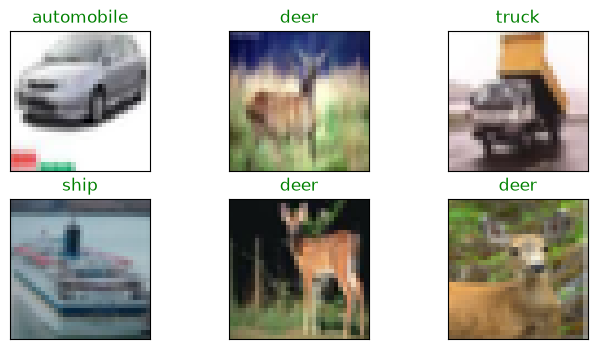

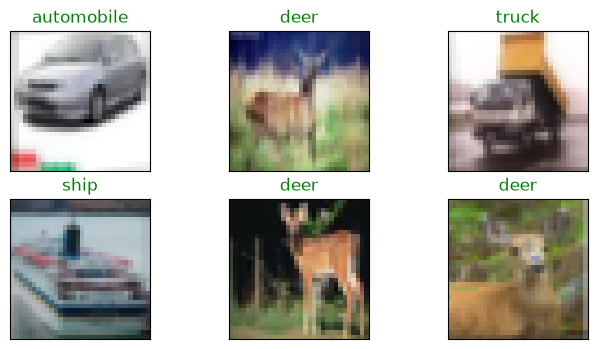

In [96]:
from PIL import Image

def im_plot (x_numpy, y_batch, transform):
    plt.figure(figsize=(8,4))
    for idx in range(6):
        im = Image.fromarray(x_numpy[idx])
        im = transform(im)

        plt.subplot(2,3, idx+1, xticks=[], yticks=[])
        plt.imshow(im.permute(1,2,0))
        true_class = test_DS.classes[y_batch[idx]]
        plt.title(true_class, color='g')

    print(f'image size = {im.shape}')

idx = torch.randint(0,10000,(6,))
x_batch = test_DS.data[idx]
target = torch.tensor(test_DS.targets)

y_batch = target[idx]
im_plot(x_batch, y_batch, transform_test)
im_plot(x_batch, y_batch, transform_train)